# Problema a resolver

## ¿Qué perfil tienen los clientes con mayor potencial de adquirir el producto?

# El set de datos
La información se encuentra en un archivo CSV (dataset_banco.csv) con 45215 filas y 17 columnas.

Cada registro contiene 16 características (las primeras 16 columnas) y una categoría ("yes" o "no" dependiendo de si la persona está o no interesada en adquirir el producto). Las columnas son:

1. "age": edad (numérica)
2. "job": tipo de trabajo (categórica: "admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student", "blue-collar","self-employed", "retired", "technician", "services")
3. "marital": estado civil (categórica: "married", "divorced", "single")
4. "education": nivel educativo (categórica: "unknown", "secondary", "primary", "tertiary")
5. "default": si dejó de pagar sus obligaciones (categórica: "yes", "no")
6. "balance": saldo promedio anual en euros (numérica)
7. "housing": ¿tiene o no crédito hipotecario? (categórica: "yes", "no")
8. "loan": ¿tiene créditos de consumo? (categórica: "yes", "no")
9. "contact": medio a través del cual fue contactado (categórica: "unknown", "telephone", "cellular")
10. "day": último día del mes en el que fue contactada (numérica)
11. "month": último mes en el que fue contactada (categórica: "jan", "feb", "mar", ..., "nov", "dec")
12. "duration": duración (en segundos) del último contacto (numérica)
13. "campaign": número total de veces que fue contactada durante la campaña (numérica)
14. "pdays": número de días transcurridos después de haber sido contactado antes de la campaña actual (numérica. -1 indica que no fue contactado previamente)
15. "previous": número de veces que ha sido contactada antes de esta campaña (numérica)
16. "poutcome": resultado de la campaña de marketing anterior (categórica: "unknown", "other", "failure", "success")
17. "y": categoría ¿el cliente se suscribió a un depósito a término? (categórica: "yes", "no")

# 1. Recolección, lectura y exploración inicial del set de datos para su comprensión

In [29]:
# Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#LINK PARA DESCARGAR EL CSV:
# https://drive.google.com/file/d/1aaGRxeeS2BLId1gtSg56tX6GnNQ-QDtX/view?usp=sharing

#Descargo csv y agrego a Colab para llamarlo directo
ruta = "dataset_banco.csv"

data = pd.read_csv(ruta)
print(data.shape) #filas y columnas
data.head() #primeros datos

(45215, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143.0,yes,no,unknown,5,may,261.0,1,-1.0,0,unknown,no
1,44,technician,single,secondary,no,29.0,yes,no,unknown,5,may,151.0,1,-1.0,0,unknown,no
2,33,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1,-1.0,0,unknown,no
3,47,blue-collar,married,unknown,no,1506.0,yes,no,unknown,5,may,92.0,1,-1.0,0,unknown,no
4,33,unknown,single,unknown,no,1.0,no,no,unknown,5,may,198.0,1,-1.0,0,unknown,no


In [30]:
 #  variables categóricas (object) y las numéricas (int64,float64)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45215 entries, 0 to 45214
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        45215 non-null  int64  
 1   job        45213 non-null  object 
 2   marital    45214 non-null  object 
 3   education  45214 non-null  object 
 4   default    45215 non-null  object 
 5   balance    45213 non-null  float64
 6   housing    45215 non-null  object 
 7   loan       45215 non-null  object 
 8   contact    45215 non-null  object 
 9   day        45215 non-null  int64  
 10  month      45215 non-null  object 
 11  duration   45214 non-null  float64
 12  campaign   45215 non-null  int64  
 13  pdays      45214 non-null  float64
 14  previous   45215 non-null  int64  
 15  poutcome   45215 non-null  object 
 16  y          45215 non-null  object 
dtypes: float64(3), int64(4), object(10)
memory usage: 5.9+ MB


puedo ver que las columnas «job», «marital», «education», «balance», «duration» y «pdays» no contienen exactamente 45.215 sino un poco menos, lo cual nos indica que estas columnas contienen datos faltantes.

# 2. LIMPIEZA de datos

Las situaciones más comunes son:

1. Datos faltantes en algunas celdas
2. Columnas irrelevantes (que no responden al problema que queremos resolver)
3. Registros (filas) repetidos
4. Valores extremos (outliers) en el caso de las variables numéricas. Se deben analizar en detalle pues no necesariamente la solución es eliminarlos
5. Errores tipográficos en el caso de las variables categóricas

In [31]:

# Como son pocos registros los que tienen valores nulos, opto por eliminar esos registros.
data.dropna(inplace=True)
data.info()

# La cantidad de registros se redujo de 45215 a 45207 (Solo se eliminaron 8 registros)


<class 'pandas.core.frame.DataFrame'>
Index: 45207 entries, 0 to 45214
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        45207 non-null  int64  
 1   job        45207 non-null  object 
 2   marital    45207 non-null  object 
 3   education  45207 non-null  object 
 4   default    45207 non-null  object 
 5   balance    45207 non-null  float64
 6   housing    45207 non-null  object 
 7   loan       45207 non-null  object 
 8   contact    45207 non-null  object 
 9   day        45207 non-null  int64  
 10  month      45207 non-null  object 
 11  duration   45207 non-null  float64
 12  campaign   45207 non-null  int64  
 13  pdays      45207 non-null  float64
 14  previous   45207 non-null  int64  
 15  poutcome   45207 non-null  object 
 16  y          45207 non-null  object 
dtypes: float64(3), int64(4), object(10)
memory usage: 6.2+ MB


# Verifico columnas irrelevantes.

In [32]:
#Verifico si hay columnas categóricas pero con un sólo nivel.
#Conteo de los niveles en las diferentes columnas categóricas
cols_cat = ['job', 'marital', 'education', 'default', 'housing',
       'loan', 'contact', 'month', 'poutcome', 'y']

for col in cols_cat:
  print(f'Columna {col}: {data[col].nunique()} subniveles')

#Todas tienen subniveles. No hago ninguna eliminación por este motivo

Columna job: 18 subniveles
Columna marital: 6 subniveles
Columna education: 10 subniveles
Columna default: 2 subniveles
Columna housing: 2 subniveles
Columna loan: 6 subniveles
Columna contact: 5 subniveles
Columna month: 12 subniveles
Columna poutcome: 6 subniveles
Columna y: 2 subniveles


In [33]:
# Verifico si las columnas numéricas tienen un único valor.
# verifico si existe alguna con su desvío estandar (std) = 0
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45207.000000,45207.000000,45207.000000,45207.000000,45207.000000,45207.000000,45207.000000
mean,41.005596,1374.201318,15.806534,258.032539,2.763731,40.178225,0.580198
std,12.037399,3924.491665,8.323015,257.460759,3.098058,100.103283,2.303341
min,18.000000,-8019.000000,1.000000,-1389.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1427.500000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,776.000000,527532.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


# Verifico filas repetidas

In [34]:
print(f'Tamaño del set antes de eliminar las filas repetidas: {data.shape}')
data.drop_duplicates(inplace=True)
print(f'Tamaño del set después de eliminar las filas repetidas: {data.shape}')

Tamaño del set antes de eliminar las filas repetidas: (45207, 17)
Tamaño del set después de eliminar las filas repetidas: (45203, 17)


# Verifico Outliers en las variables numericas

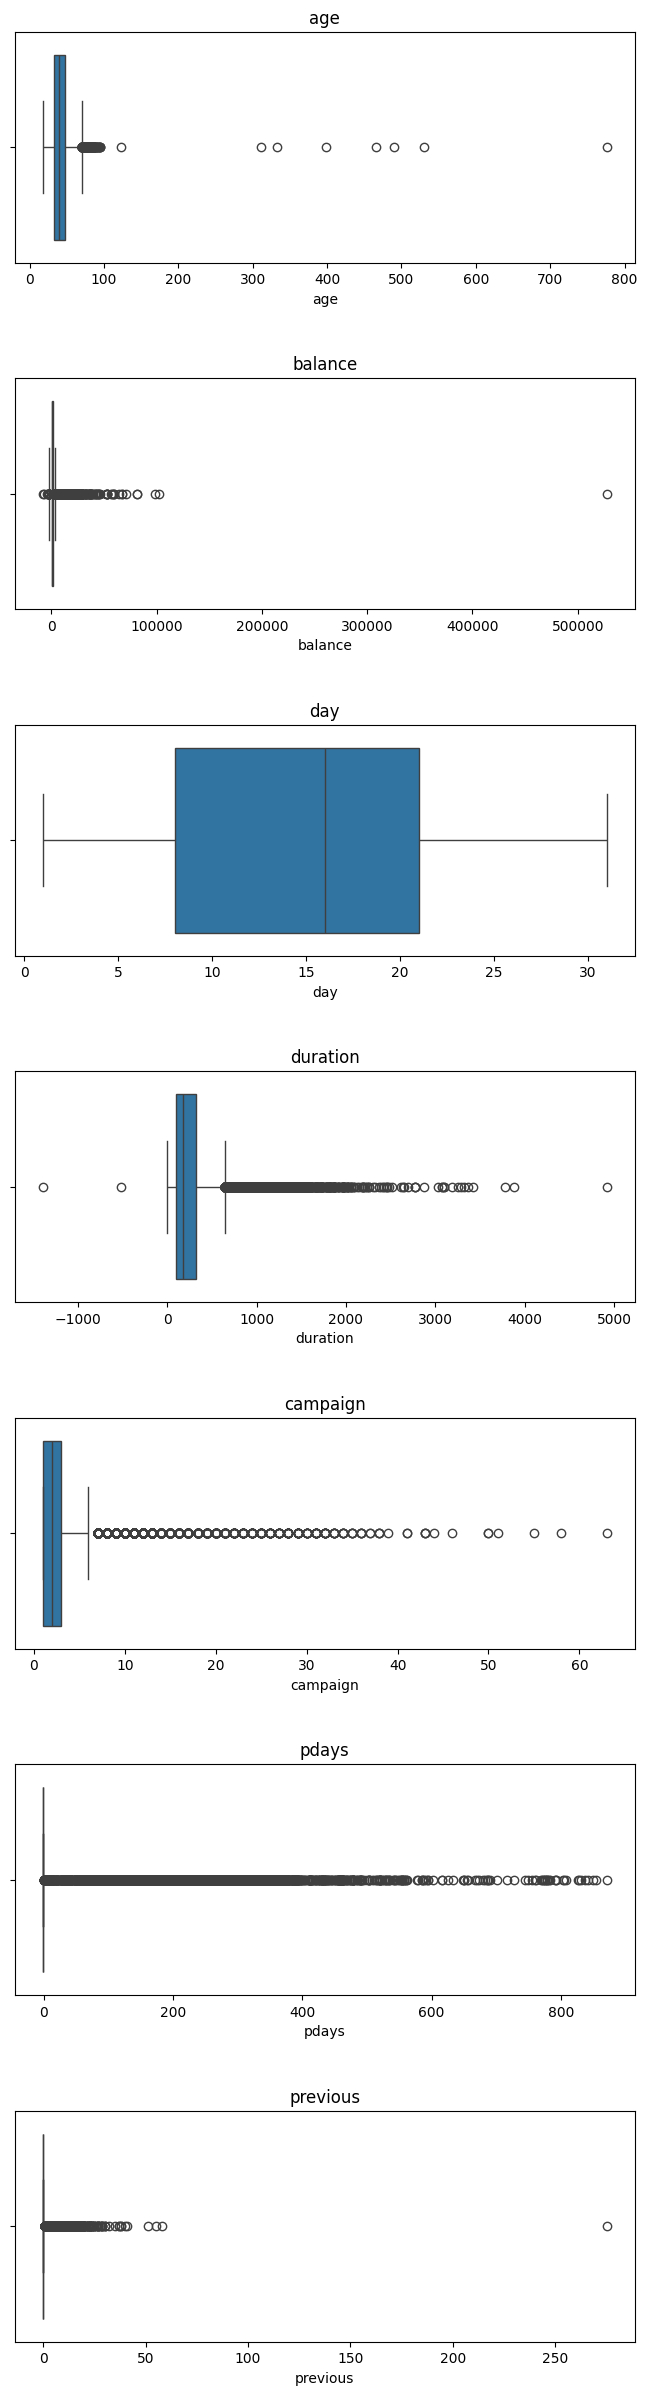

In [35]:
# Generar gráficas individuales pues las variables numéricas
# están en rangos diferentes
cols_num = ['age', 'balance', 'day', 'duration', 'campaign',
            'pdays', 'previous']

fig, ax = plt.subplots(nrows=7, ncols=1, figsize=(8,30))
fig.subplots_adjust(hspace=0.5)

for i, col in enumerate(cols_num):
    sns.boxplot(x=col, data=data, ax=ax[i])
    ax[i].set_title(col)

**Observaciones:**
- "age": hay sujetos con edades mucho mayores a 100 años
- "duration": hay valores negativos en llamadas telefónicas
- "previous": hay un valor extremadamente alto (cercano a 300)

In [36]:
# Eliminar filas con "age">100
print(f'Tamaño del set antes de eliminar registros de edad: {data.shape}')
data = data[data['age']<=100]
print(f'Tamaño del set después de eliminar registros de edad: {data.shape}')

Tamaño del set antes de eliminar registros de edad: (45203, 17)
Tamaño del set después de eliminar registros de edad: (45195, 17)


In [37]:
# Eliminar filas con "duration"<0
print(f'Tamaño del set antes de eliminar registros de duración: {data.shape}')
data = data[data['duration']>0]
print(f'Tamaño del set después de eliminar registros de duración: {data.shape}')

Tamaño del set antes de eliminar registros de duración: (45195, 17)
Tamaño del set después de eliminar registros de duración: (45190, 17)


In [38]:
# Eliminar filas con "previous">100 - Asumo que es un error de carga haber llamado más de 100 veces a una persona
print(f'Tamaño del set antes de eliminar registros de previous: {data.shape}')
data = data[data['previous']<=100]
print(f'Tamaño del set después de eliminar registros de previous: {data.shape}')

Tamaño del set antes de eliminar registros de previous: (45190, 17)
Tamaño del set después de eliminar registros de previous: (45189, 17)


# Errores tipográficos en las variables categóricas

Busco valores equivalentes pero escritos de forma distinta

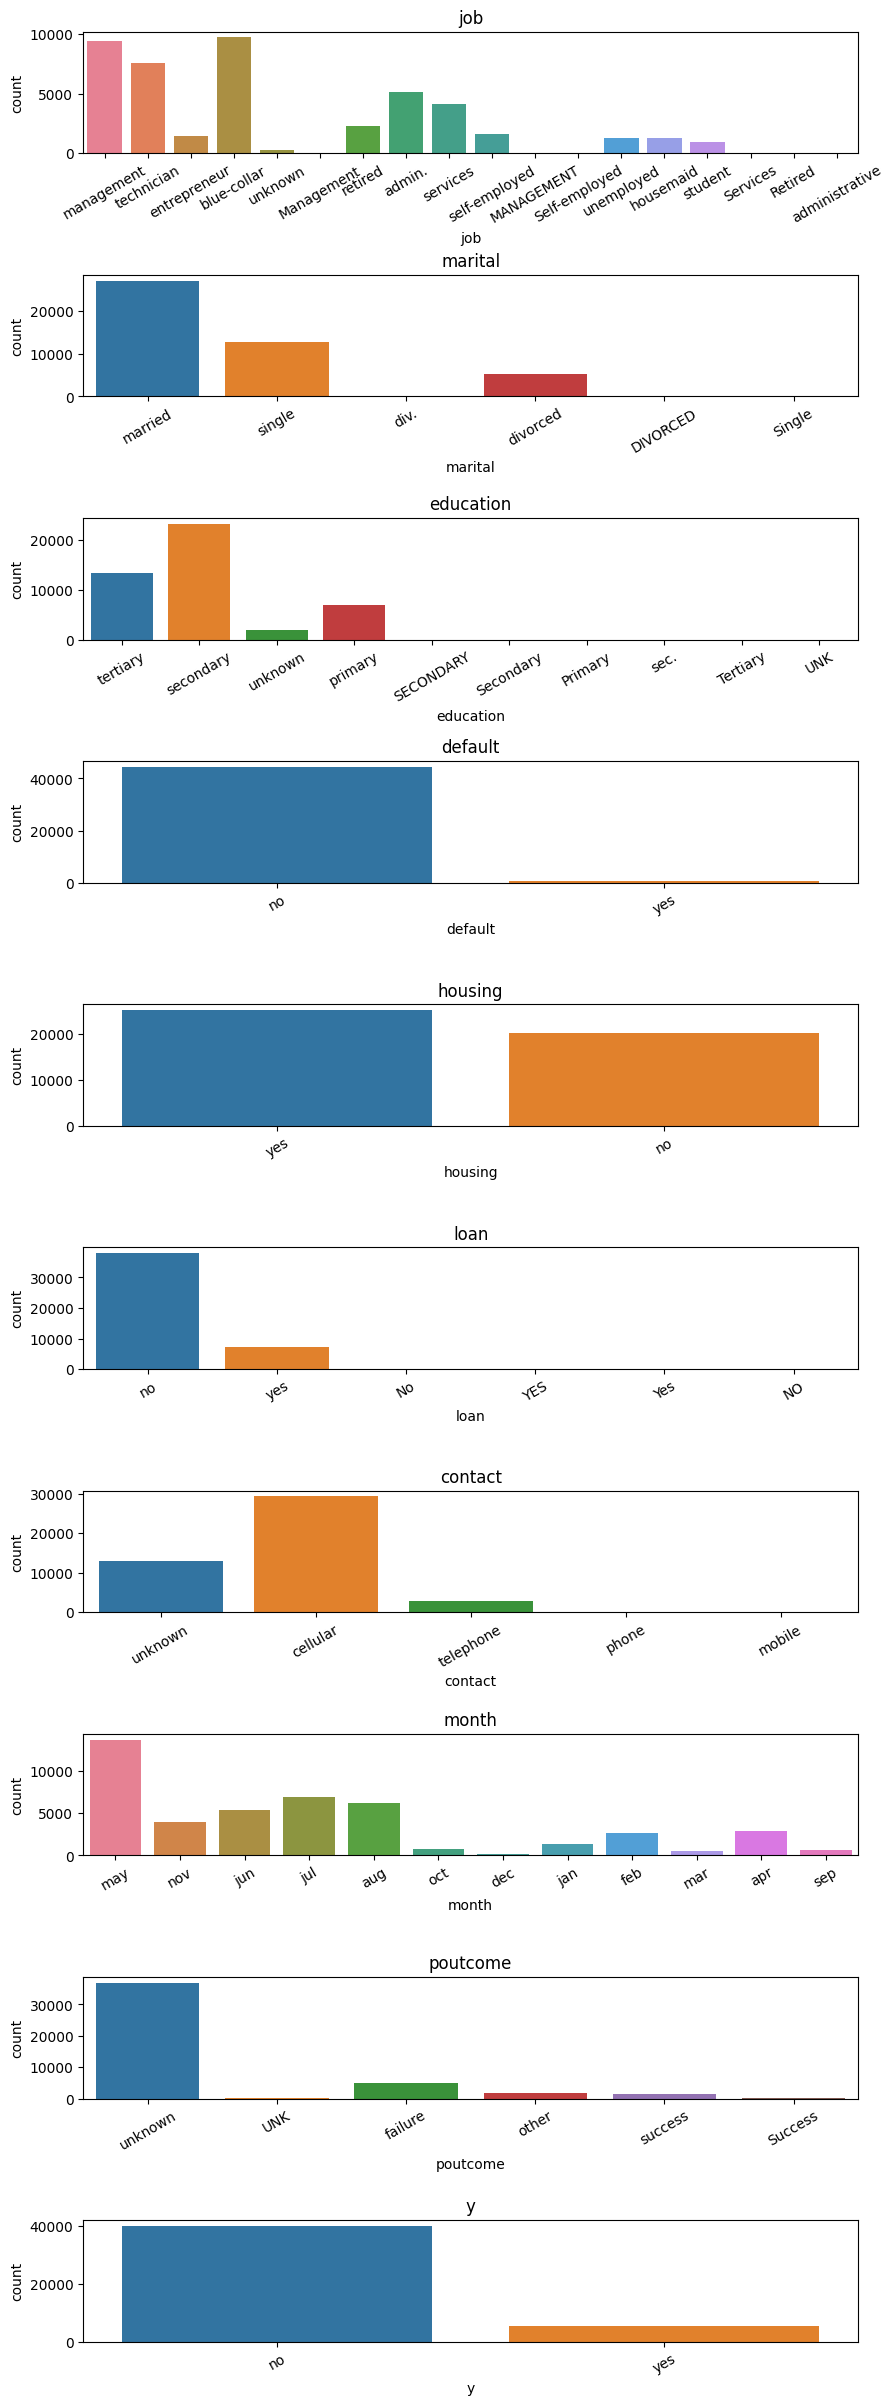

In [39]:
# Grafico los subniveles de cada variable categórica
cols_cat = ['job', 'marital', 'education', 'default', 'housing',
       'loan', 'contact', 'month', 'poutcome', 'y']

fig, ax = plt.subplots(nrows=10, ncols=1, figsize=(10,30))
fig.subplots_adjust(hspace=1)

for i, col in enumerate(cols_cat):
  #sns.countplot(x=col, data=data, ax=ax[i]) - Grafico sin color
  sns.countplot(x=col, data=data, ax=ax[i], hue=col, legend=False)
  ax[i].set_title(col)
  #ax[i].set_xticklabels(ax[i].get_xticklabels(),rotation=30)
  ax[i].tick_params(axis='x', rotation=30)

Inicialmente se observa que hay sub-niveles con el mismo nombre pero escritos en minúscula, en mayúscula o con la primera letra en mayúscula.

Unifico estos sub-niveles

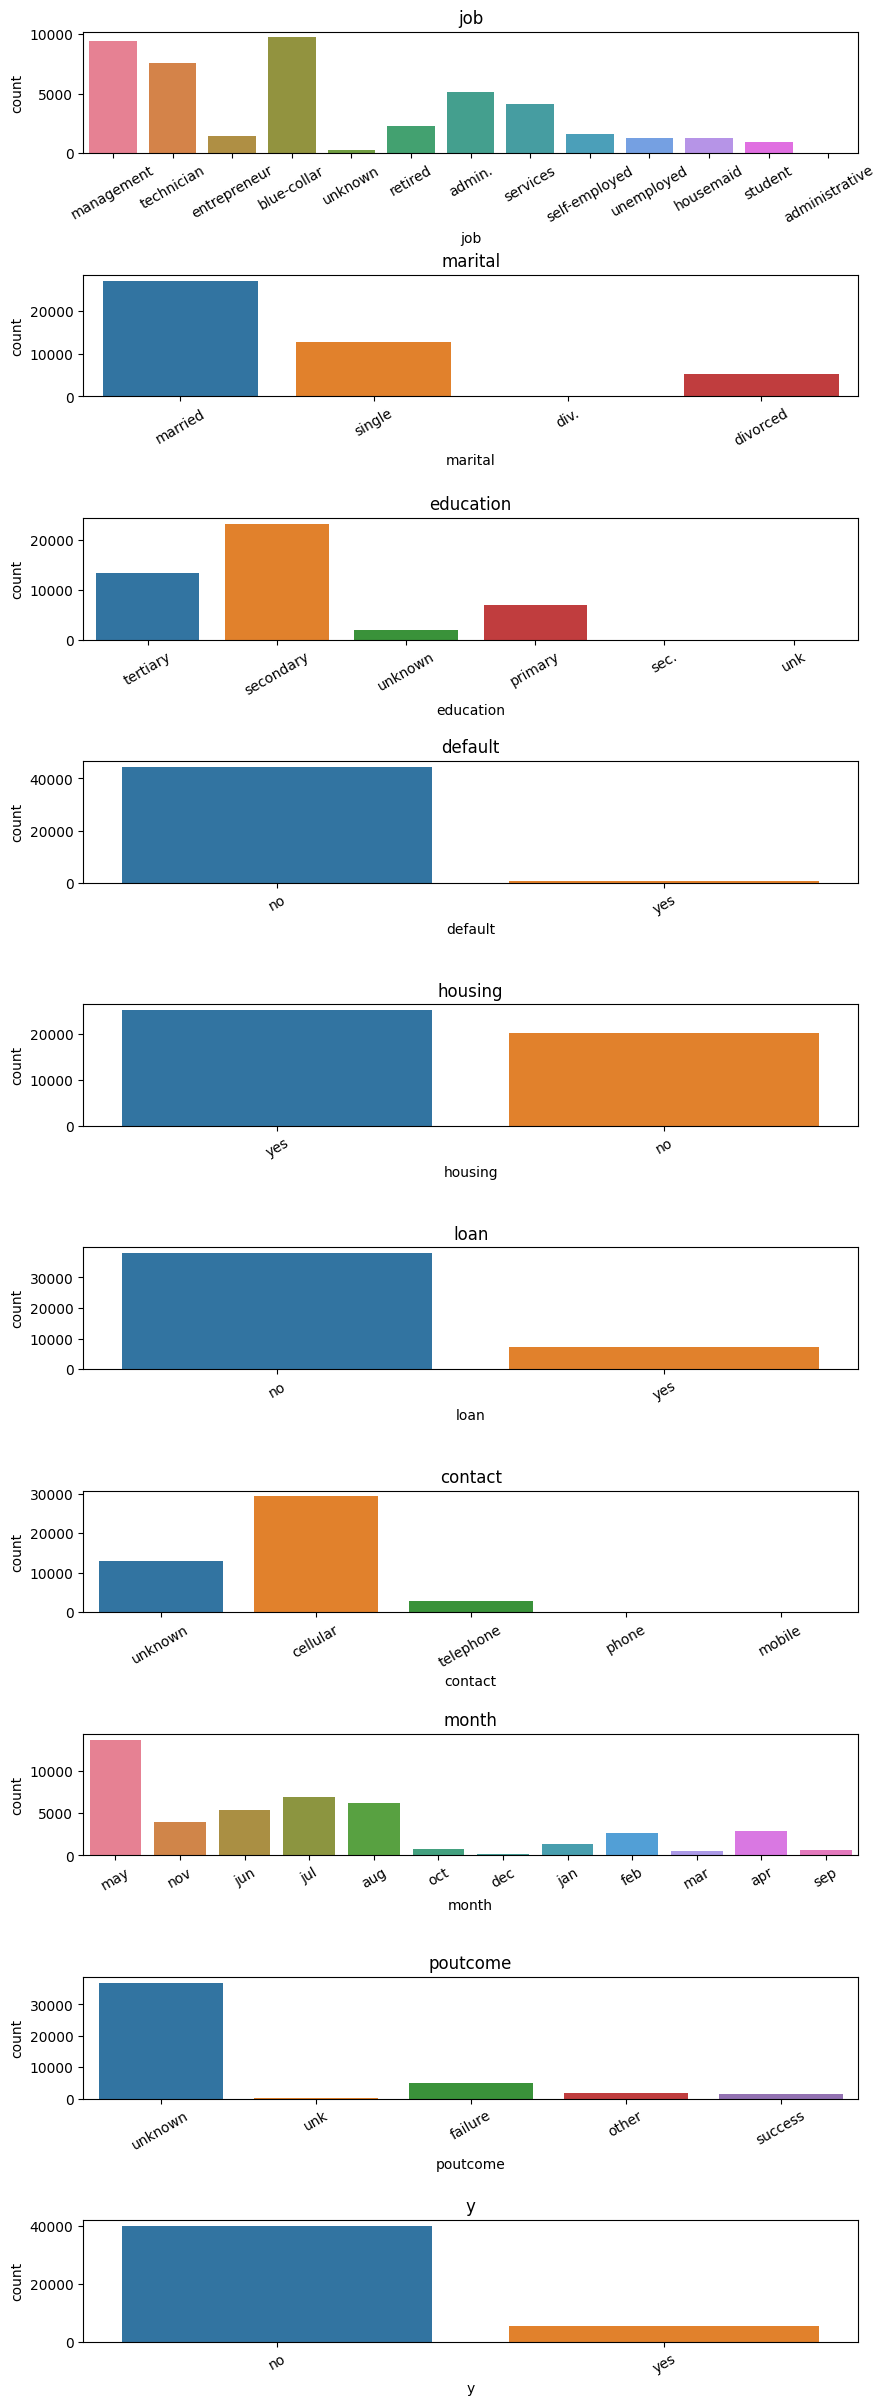

In [40]:
for column in data.columns:
    # Representar en minúsculas sólo si la columna es categórica
    if column in cols_cat:
        data[column] = data[column].str.lower()

# Y generemos las gráficas nuevamente
fig, ax = plt.subplots(nrows=10, ncols=1, figsize=(10,30))
fig.subplots_adjust(hspace=1)

for i, col in enumerate(cols_cat):
  sns.countplot(x=col, data=data, ax=ax[i], hue=col, legend=False)
  ax[i].set_title(col)
  ax[i].tick_params(axis='x', rotation=30)

In [41]:
#job: unificar admin. y administrative.
print(data['job'].unique())
data['job'] = data['job'].replace(['admin.','administrative.'],'administrative')
#administrative. no existe, pero para demostrar que se pueden agregar varios valores a corregir
print(data['job'].unique())


['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student' 'administrative']
['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'administrative' 'services' 'self-employed' 'unemployed'
 'housemaid' 'student']


In [42]:
#marital: unificar div. y divorced
print(data['marital'].unique())
data['marital'] = data['marital'].replace(['div.','divorced'],'divorced')
print(data['marital'].unique())

['married' 'single' 'div.' 'divorced']
['married' 'single' 'divorced']


In [43]:
#education: unificar sec. y secondary, unk y unknown
print(data['education'].unique())
data['education'] = data['education'].replace(['sec.','secondary'],'secondary')
data['education'] = data['education'].replace(['unk','unknown'],'unknown')
print(data['education'].unique())

['tertiary' 'secondary' 'unknown' 'primary' 'sec.' 'unk']
['tertiary' 'secondary' 'unknown' 'primary']


In [44]:
#contact: unificar telephone y phone
print(data['contact'].unique())
data['contact'] = data['contact'].replace(['telephone','phone'],'telephone')
print(data['contact'].unique())

['unknown' 'cellular' 'telephone' 'phone' 'mobile']
['unknown' 'cellular' 'telephone' 'mobile']


In [45]:
#poutcome: unificar unknown y unk
print(data['poutcome'].unique())
data['poutcome'] = data['poutcome'].replace(['unknown','unk'],'unknown')
print(data['poutcome'].unique())

['unknown' 'unk' 'failure' 'other' 'success']
['unknown' 'failure' 'other' 'success']


# ¿Cómo queda el dataset luego de la limpieza?

In [46]:
data.shape

(45189, 17)

#Genero graficos independientes y los descargo al equipo para guardarlos en nombre_proyecto/reports

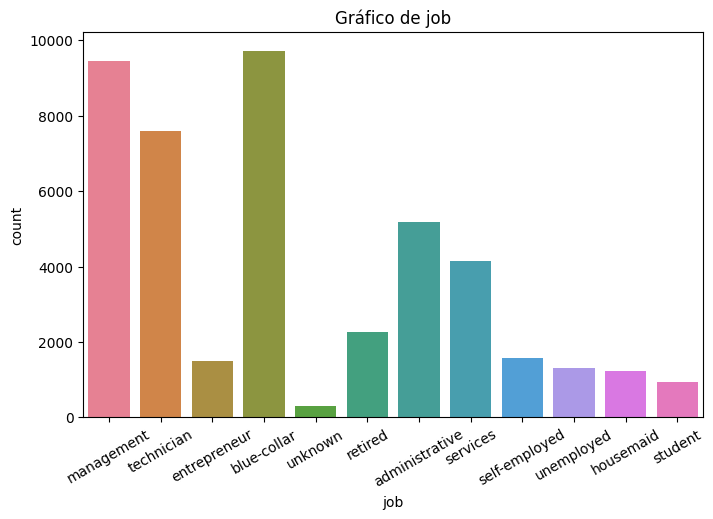

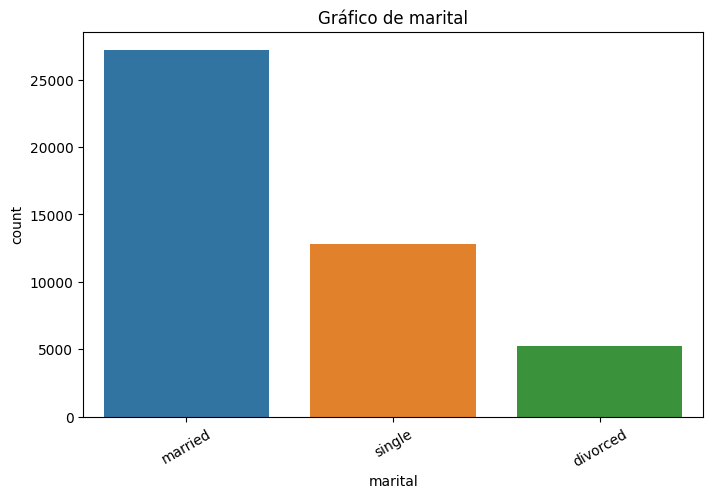

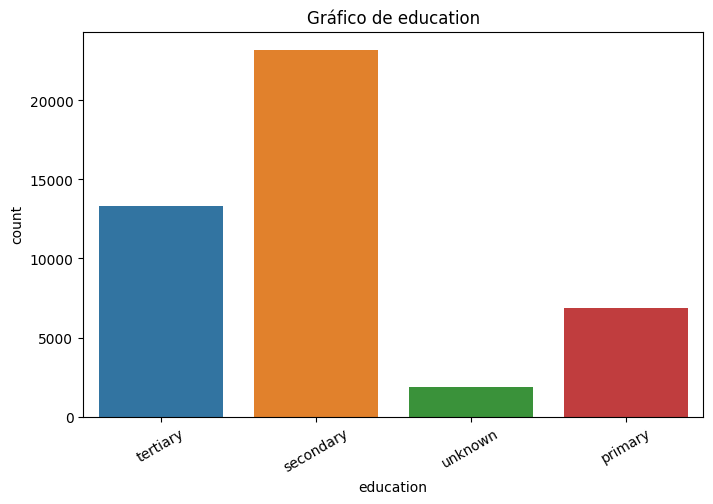

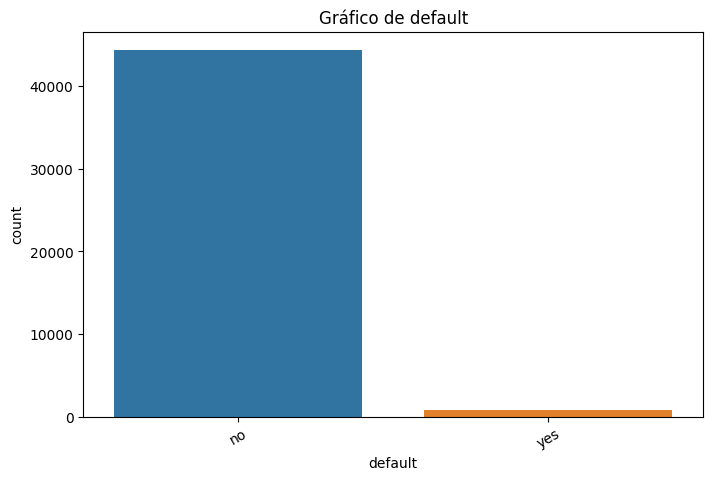

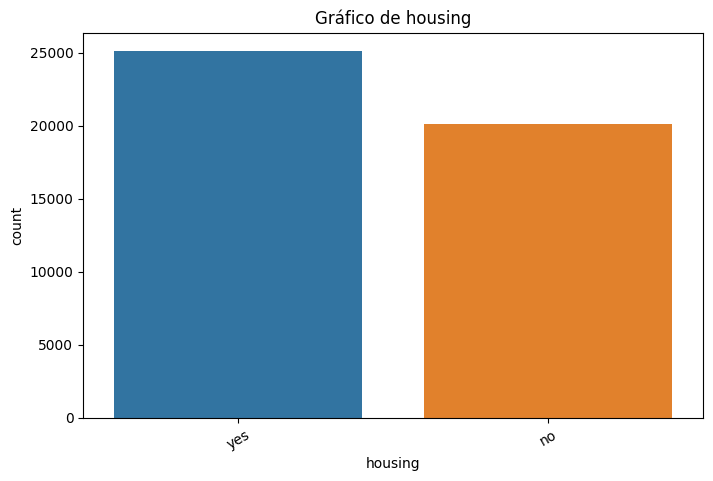

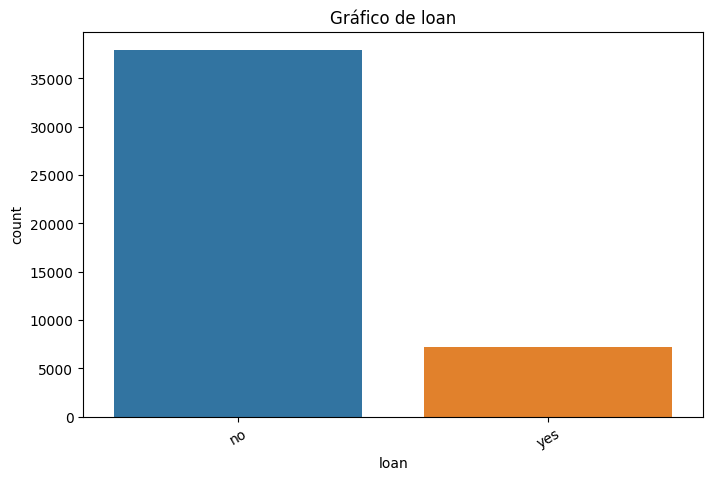

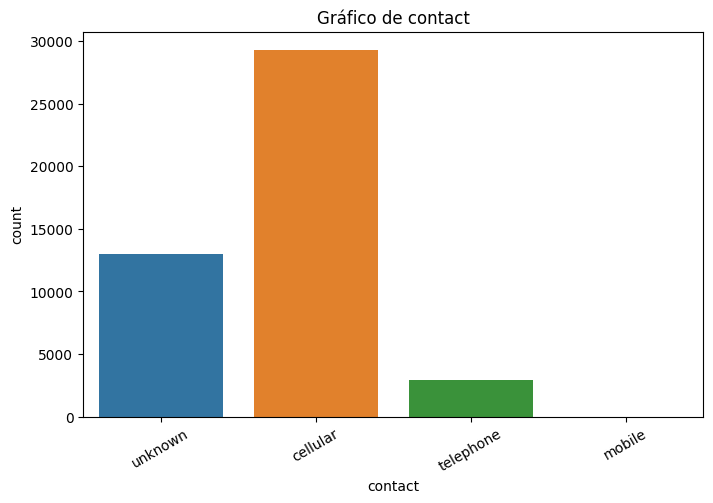

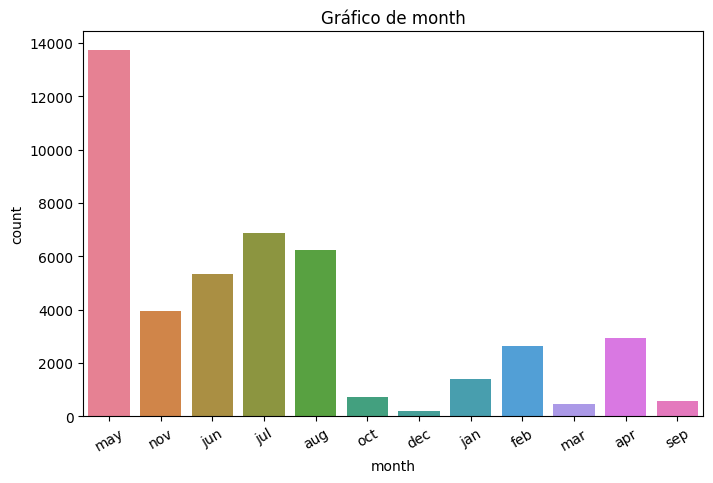

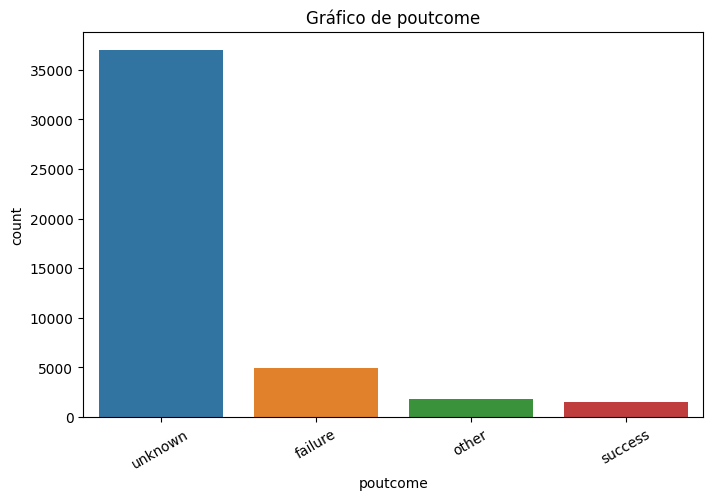

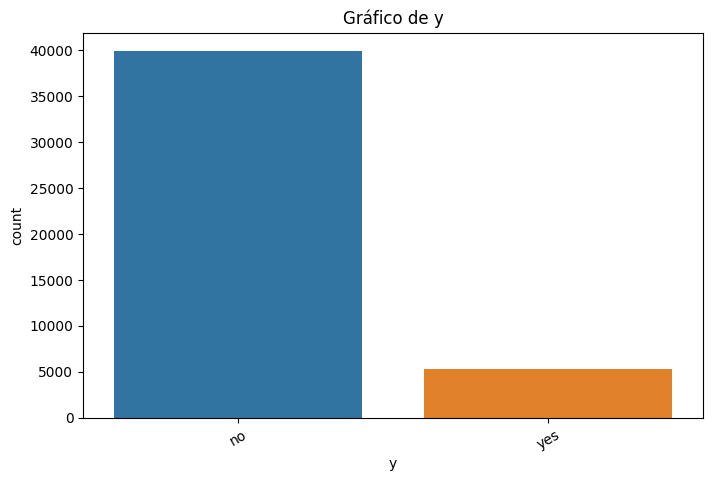

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Recorremos cada columna categórica
for col in cols_cat:
    # 1. Crear una figura nueva y exclusiva para esta variable
    fig, ax = plt.subplots(figsize=(8, 5))

    # 2. Hacer el gráfico en su propio eje
    sns.countplot(x=col, data=data, ax=ax, hue=col, legend=False)
    ax.set_title(f"Gráfico de {col}")
    ax.tick_params(axis='x', rotation=30)

    # 3. MOSTRAR el gráfico en pantalla en cada iteración
    plt.show()

    # 4. Guardar el archivo individual limpio
    nombre_archivo = f"grafico_{col}.png"
    fig.savefig(nombre_archivo, dpi=300, bbox_inches='tight')

    # 5. Cerrar la figura para liberar memoria RAM
    plt.close(fig)

# 6. Forzar la descarga directa de todos los gráficos generados a tu PC
for col in cols_cat:
    files.download(f"grafico_{col}.png")

# Guardo el dataset limpio generado

In [48]:
#Descargo el dataset limpio en mi pc para guardarlo en nombre_proyecto\data\processed"
# 1. Guardar temporalmente el archivo dentro de Colab
nombre_archivo = "dataset_banco_limpio.csv"
data.to_csv(nombre_archivo, index=False)

# 2. Forzar la descarga directa
from google.colab import files
files.download(nombre_archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Descargo el archivo .ipynb y lo guardo en nombre_proyecto/notebooks

1. Archivo
2. Descargar --> Descargar .ipynb